In [14]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
"""Đọc file CSV"""

In [3]:
df_diabetes = pd.read_csv("diabetes.csv")

print("Kích thước:", df_diabetes.shape)
display(df_diabetes.head())
print("\nTên cột:")
print(df_diabetes.columns.tolist())

print("\nGiá trị thiếu:")
print(df_diabetes.isnull().sum())

Kích thước: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



Tên cột:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Giá trị thiếu:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [ ]:
"""Khám phá và trực quan hóa dữ liệu"""

,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.074850,0.263150,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039420,0.194593,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085000,0.278883,0.00,0.00,0.00,0.00,1.00



Phân bố nhãn:
diabetes
0    91500
1     8500
Name: count, dtype: int64


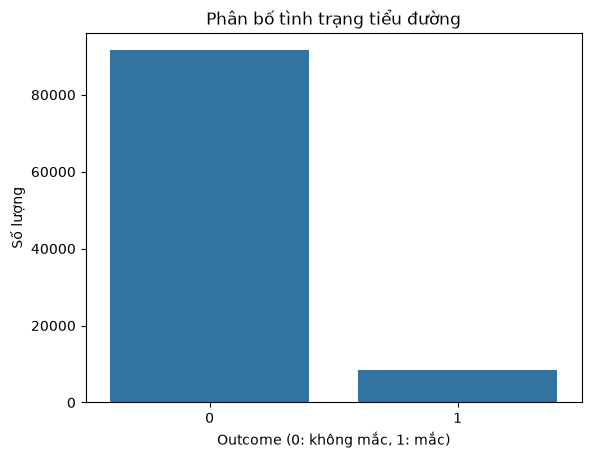

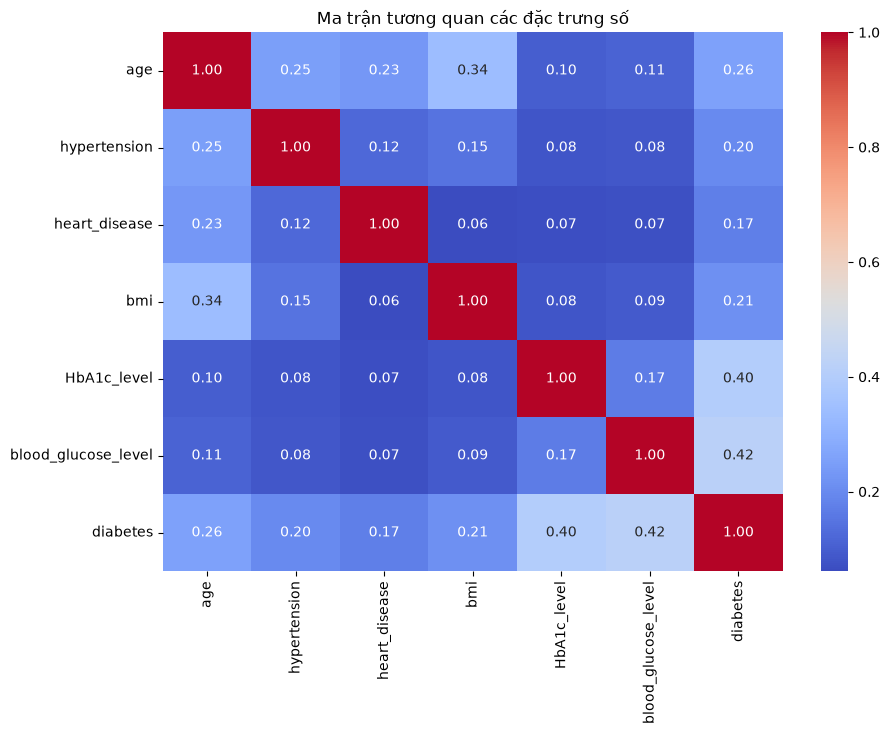

In [6]:
display(df_diabetes.describe().T)

print("\nPhân bố nhãn:")
print(df_diabetes["diabetes"].value_counts())

sns.countplot(data=df_diabetes, x="diabetes")
plt.title("Phân bố tình trạng tiểu đường")
plt.xlabel("Outcome (0: không mắc, 1: mắc)")
plt.ylabel("Số lượng")
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(
    df_diabetes.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Ma trận tương quan các đặc trưng số")
plt.show()

In [ ]:
"""Tiền xử lý và chia dữ liệu"""

In [7]:
df = df_diabetes.copy()

target_col = "diabetes"

X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

# Áp dụng riêng cho tập Pima cổ điển nếu các cột này tồn tại
zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in zero_as_missing:
    if col in X.columns:
        X[col] = X[col].replace(0, np.nan)

# Chia trước để tránh dùng thông tin từ test khi xử lý dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (80000, 8)
Test: (20000, 8)


In [ ]:
"""Huấn luyện SVM có xử lý giá trị thiếu"""

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer

Các cột số: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Các cột phân loại: ['gender', 'smoking_history']
Accuracy: 0.8963

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     18300
           1       0.45      0.92      0.60      1700

    accuracy                           0.90     20000
   macro avg       0.72      0.91      0.77     20000
weighted avg       0.95      0.90      0.91     20000



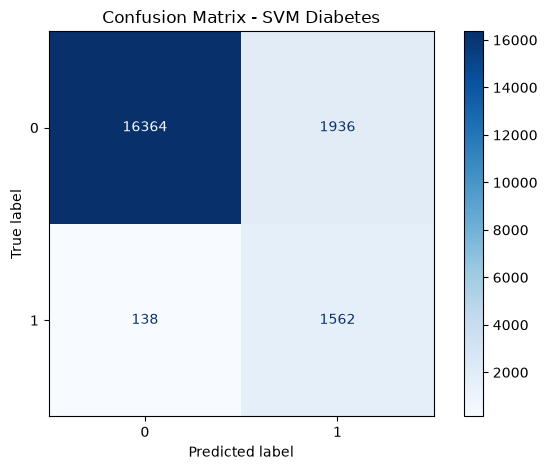

In [21]:

# 1. Xác định dữ liệu đầu vào và nhãn
X = df_diabetes.drop(columns=["diabetes"]).copy()
y = df_diabetes["diabetes"].copy()

# Loại bỏ các dòng không có nhãn
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# 2. Khai báo rõ các cột theo đúng bộ dữ liệu của cậu chủ
numeric_cols = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

categorical_cols = [
    "gender",
    "smoking_history"
]

# Chuyển các cột số về kiểu số nếu chúng đang được lưu dưới dạng chữ
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("Các cột số:", numeric_cols)
print("Các cột phân loại:", categorical_cols)

# 3. Xử lý dữ liệu số
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 4. Xử lý dữ liệu phân loại
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 5. Kết hợp hai quy trình tiền xử lý
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# 6. Chia tập huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 7. Xây dựng mô hình SVM
svm_diabetes = Pipeline([
    ("preprocessor", preprocessor),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    ))
])

# 8. Huấn luyện mô hình
svm_diabetes.fit(X_train, y_train)

# 9. Dự đoán
y_pred_diabetes = svm_diabetes.predict(X_test)

# 10. Đánh giá mô hình
print("Accuracy:", round(
    accuracy_score(y_test, y_pred_diabetes), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_diabetes,
    zero_division=0
))

# 11. Vẽ ma trận nhầm lẫn
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_diabetes,
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - SVM Diabetes")
plt.tight_layout()
plt.show()